# P2 / 02: high abnormal volume reverses more? (H2, independent sample 2017–2019)

Protocol: [`001_claude_p2_liquidity_provision_preregistration.md`](../../discussions/Liquidity_Provision/001_claude_p2_liquidity_provision_preregistration.md), section 4. The P1 observation (2020–2025, post hoc) re-tested on data P1 did not use.

Same construction as P1 arm D at k = 5: abnormal-volume terciles (T1 low … T3 high), quintile sort on the past 5-session return within each tercile, reversal = long bottom / short top, overlapping 5-session holding, one-session skip.

**Gates** (α = 0.025): A1 gross T3 − T1 > 0 (block bootstrap lower bound > 0 at blocks 10/20/40); A2 observed T3 − T1 above 500 shuffled-label placebos (upper-tail p ≤ α). 2020–2025 is shown for reference only.

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P2_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p2.P2Config()
PER_YEAR, WINDOW_S = 4, 3.0                          # S05b quote samples (reused from cache)
YEARS_D = list(range(2016, 2026))                    # 1Day bars; 2016 is baseline warm-up
YEARS_Q = list(range(2020, 2026))                    # measured-cost years; 2026 not used
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"15Min_w{WINDOW_S:g}s"
tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_p2{p2.P2_VERSION}"
OUT = ROOT / "notebooks" / "Liquidity_Provision" / ("02_synthetic" if SYNTHETIC else "02")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "p2" / tag
CACHE.mkdir(parents=True, exist_ok=True)
N_JOBS = -1
GNAME = {0: "T1 low AV", 1: "T2", 2: "T3 high AV"}
GCOL = {0: "#2a78d6", 1: "#8a8a84", 2: "#eb6834"}

## 1. Data (as notebook 01)

In [2]:
t0 = time.time()
if SYNTHETIC:
    C, V, VIX = p2.synthetic_daily_vix(n_stocks=150, years=list(range(2016, 2022)), slope=0.25)
    COST = pd.DataFrame(3e-4, index=C.index, columns=C.columns)
    CFG = replace(CFG, end="2021-12-31", n_label_placebo=20, n_boot=2000)
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    STOCKS = sorted(constituents["Symbol"])
    download_years(STOCKS, "1Day", YEARS_D, workers=8)
    C, _, V = p1.load_daily(STOCKS, YEARS_D)
    C, V = C.dropna(axis=1, how="all"), V.dropna(axis=1, how="all")
    VIX = p2.load_vix()
    SESSIONS = s05b.sample_sessions(YEARS_Q, PER_YEAR, seed=42)
    missing = [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]
    if missing:
        QUOTE_CACHE.mkdir(parents=True, exist_ok=True)
        for d in missing:
            sample_quote_spreads(list(C.columns), d, s05b.slot_starts(YEARS_Q, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
    COST = p1.daily_cost(C.index, list(C.columns), s05b.cost_model(samples))   # 2016-2019: per-symbol fallback (no quotes)
RET = C.pct_change()
VIX = VIX.reindex(C.index).ffill(limit=2)
REG = p2.vix_regime(VIX, CFG)
print(f"{C.shape[1]} stocks, {len(C)} sessions {C.index[0].date()} to {C.index[-1].date()}; VIX coverage "
      f"{VIX.notna().mean():.1%}; high-regime share {REG.mean():.1%}; ready in {time.time() - t0:.0f}s")

1Day: 0 batches to download (0 symbol-years), 8 parallel requests
501 stocks, 2514 sessions 2016-01-04 to 2025-12-31; VIX coverage 100.0%; high-regime share 46.3%; ready in 35s


## 2. Tercile reversal portfolios, 2017–2019 (judged) and 2020–2025 (reference)

gross_bps_day  net_bps_day_at_2020s_cost  sharpe_gross
window    tercile                                                           
2017-2019 T1 low AV           3.484                      1.764         0.952
          T2                  3.321                      1.685         0.924
          T3 high AV          2.648                      1.006         0.684
2020-2025 T1 low AV           1.153                     -0.650         0.170
          T2                  2.570                      0.788         0.407
          T3 high AV          5.383                      3.650         0.637

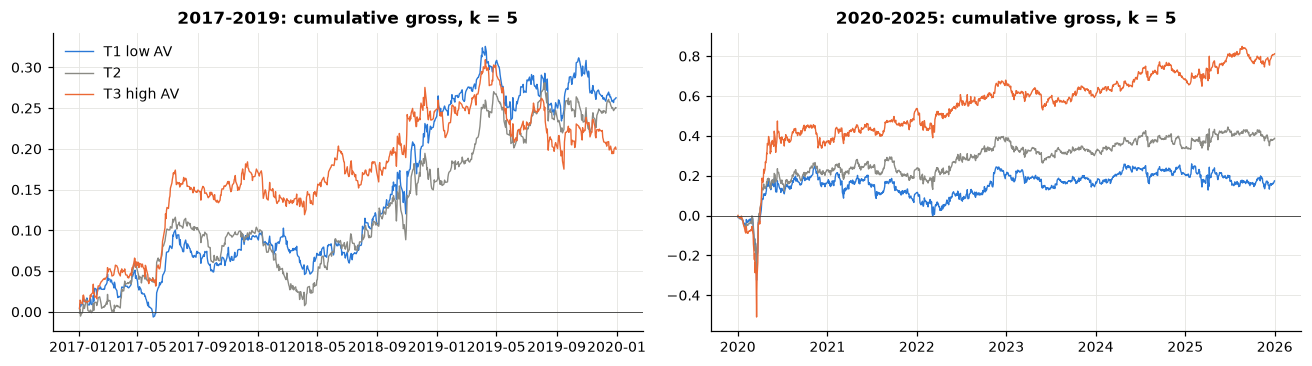

In [3]:
PC = p1.P1Config(horizons=(CFG.h2_k,))
AV = p1.abnormal_volume(V, PC)
K = CFG.h2_k
SIG = np.log(C / C.shift(K))
LAB = p1.group_labels(AV, 3, eligible=(C >= CFG.min_price) & SIG.notna())
WINS = {"2017-2019": C.index[(C.index >= CFG.h2_start) & (C.index <= CFG.h2_end)],
        "2020-2025": C.index[(C.index >= CFG.econ_start) & (C.index <= CFG.end)]}
RES, ROWS = {}, []
for name, win in WINS.items():
    if len(win) == 0:
        continue
    RES[name] = p1.arm_d_horizon(SIG, LAB, RET, COST, K, PC, win)
    for g, df in RES[name].items():
        ROWS.append({"window": name, "tercile": GNAME[g], "gross_bps_day": 1e4 * df.gross.mean(),
                     "net_bps_day_at_2020s_cost": 1e4 * df.net.mean(),
                     "sharpe_gross": np.sqrt(252) * df.gross.mean() / df.gross.std()})
    pd.concat({GNAME[g]: df for g, df in RES[name].items()}, axis=1).to_csv(OUT / f"daily_returns_{name}.csv", float_format="%.6g")
TAB = pd.DataFrame(ROWS).set_index(["window", "tercile"])
display(TAB.round(3))
fig, ax = plt.subplots(1, len(RES), figsize=(6 * len(RES), 3.4))
for a, (name, res) in zip(np.atleast_1d(ax), RES.items()):
    for g, df in res.items():
        a.plot(df.index, df.gross.cumsum(), color=GCOL[g], lw=0.9, label=GNAME[g])
    a.axhline(0, color="#444", lw=0.6); a.set_title(f"{name}: cumulative gross, k = {K}")
np.atleast_1d(ax)[0].legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Gates on 2017–2019

In [4]:
from joblib import Parallel, delayed
J = "2017-2019"
diff = (RES[J][2].gross - RES[J][0].gross).to_numpy()
BOOT = {b: p1.block_bootstrap(diff, b, CFG.n_boot, CFG.seed, CFG.alpha) for b in CFG.blocks}
pl_path = CACHE / f"label_placebo_h2_{CFG.n_label_placebo}.npy"
if pl_path.exists():
    dist = np.load(pl_path)
else:
    t0 = time.time()
    chunks = [(i, min(25, CFG.n_label_placebo - i)) for i in range(0, CFG.n_label_placebo, 25)]
    dist = np.concatenate(Parallel(n_jobs=N_JOBS)(delayed(p1.label_placebo)(SIG, LAB, RET, K, PC, WINS[J], n, CFG.seed * 1000 + i)
                                                  for i, n in chunks))
    np.save(pl_path, dist); print(f"{len(dist)} placebos in {(time.time() - t0) / 60:.1f} min")
obs_low_minus_high = -float(diff.mean())
p_upper = float((1 + np.sum(dist <= obs_low_minus_high)) / (len(dist) + 1))   # T3 - T1 large <=> T1 - T3 small
REF = {b: p1.block_bootstrap((RES["2020-2025"][2].gross - RES["2020-2025"][0].gross).to_numpy(), b, CFG.n_boot, CFG.seed, CFG.alpha)
       for b in CFG.blocks} if "2020-2025" in RES else {}
G = p2.gates_h2(BOOT, p_upper, CFG.alpha)
display((pd.concat({"2017-2019": pd.DataFrame(BOOT, index=["mean", "lo", "hi"]).T,
                    **({"2020-2025 (reference)": pd.DataFrame(REF, index=["mean", "lo", "hi"]).T} if REF else {})}) * 1e4).round(3))
print(f"T3 - T1 = {1e4 * diff.mean():.3f} bps/day; shuffled-label upper-tail p = {p_upper:.4f}")
display(pd.Series(G))
pd.Series(-dist, name="T3_minus_T1_gross_mean").to_csv(OUT / "label_placebo.csv", index=False, float_format="%.6g")
summary = {"study": "P2-02", "synthetic": SYNTHETIC, "config": CFG.as_dict(), "table": {f"{w}|{t}": v for (w, t), v in TAB.to_dict(orient="index").items()},
           "T3_minus_T1_bps_day": 1e4 * float(diff.mean()), "bootstrap_bps": {str(k): [1e4 * x for x in v] for k, v in BOOT.items()},
           "reference_2020_2025_bps": {str(k): [1e4 * x for x in v] for k, v in REF.items()}, "label_placebo_p_upper": p_upper, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "p2": p2.P2_VERSION, "p1": p1.P1_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps(G, indent=2))

mean     lo     hi
2017-2019             10 -0.837 -4.581  2.797
                      20 -0.837 -4.524  2.654
                      40 -0.837 -4.430  2.624
2020-2025 (reference) 10  4.230 -0.227  8.954
                      20  4.230 -0.434  9.399
                      40  4.230 -0.382  9.866

T3 - T1 = -0.837 bps/day; shuffled-label upper-tail p = 0.8044


A1_bootstrap                False
A2_label_placebo            False
verdict             NOT_CONFIRMED
dtype: object

{
  "A1_bootstrap": false,
  "A2_label_placebo": false,
  "verdict": "NOT_CONFIRMED"
}
